## Exploratory Data Analysis

In [1]:
import pandas as pd     
import geopandas as gpd   
import matplotlib.pyplot as plt  
import seaborn as sns   
import numpy as np
import os

### Paths

In [2]:

script_dir=os.path.dirname(os.path.abspath('__file__'))
project_dir=os.path.dirname(script_dir)
data_dir=os.path.join(project_dir, 'Data')
output_dir=os.path.join(project_dir, 'EDA_outputs')
os.makedirs(output_dir, exist_ok=True)

crime_path=os.path.join(data_dir, 'crime_monthly_lsoa.csv')
shapefile_path=os.path.join(data_dir, 'shapefile', 'LSOA_2021_EW_BGC_V5.shp')



### Loading data

In [3]:

crime=pd.read_csv(crime_path)
gdf=gpd.read_file(shapefile_path)

#Filtering shapefile to Teesside LSOAs
teesside_codes=crime['LSOA code'].unique()
teesside_gdf=gdf[gdf['LSOA21CD'].isin(teesside_codes)].copy()

print(f"Crime data: {len(crime):,} rows, {crime['LSOA code'].nunique()} LSOAs, {crime['Month'].nunique()} months")
print(f"Shapefile matched {len(teesside_gdf)} LSOAs out of {len(teesside_codes)}")
print(f"Total crimes: {crime['crime_count'].sum():,}")

#Setting style
sns.set_style('whitegrid')

Crime data: 13,284 rows, 369 LSOAs, 36 months
Shapefile matched 359 LSOAs out of 369
Total crimes: 274,344


### Chart 1: Overall crime trend over 36 months

Chart 1:


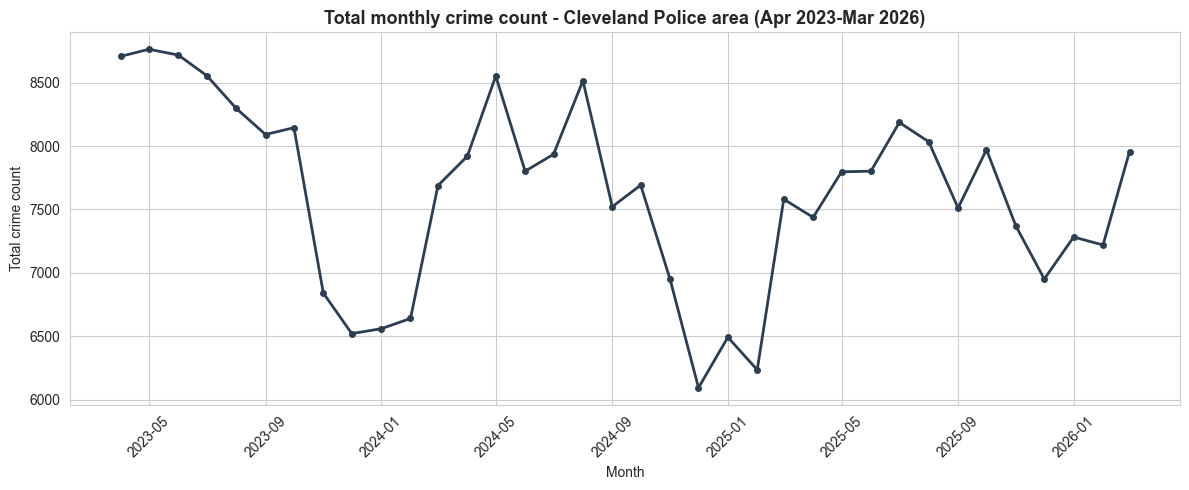

Plot_1_crime_trend is saved in EDA_outputs folder


In [4]:

print("Chart 1:")

monthly_total=crime.groupby('Month')['crime_count'].sum().reset_index()
monthly_total['Month_dt']=pd.to_datetime(monthly_total['Month'])


fig, ax=plt.subplots(figsize=(12,5))
ax.plot(monthly_total['Month_dt'], monthly_total['crime_count'], color='#2c3e50',
        linewidth=2, marker='o', markersize=4)
ax.set_title('Total monthly crime count - Cleveland Police area (Apr 2023-Mar 2026)', fontsize=13,fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Total crime count')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_1_crime_trend.png'), dpi=150)
plt.show()
print("Plot_1_crime_trend is saved in EDA_outputs folder")



### Plot 2: Crime trend by Local Authority

Plot 2:


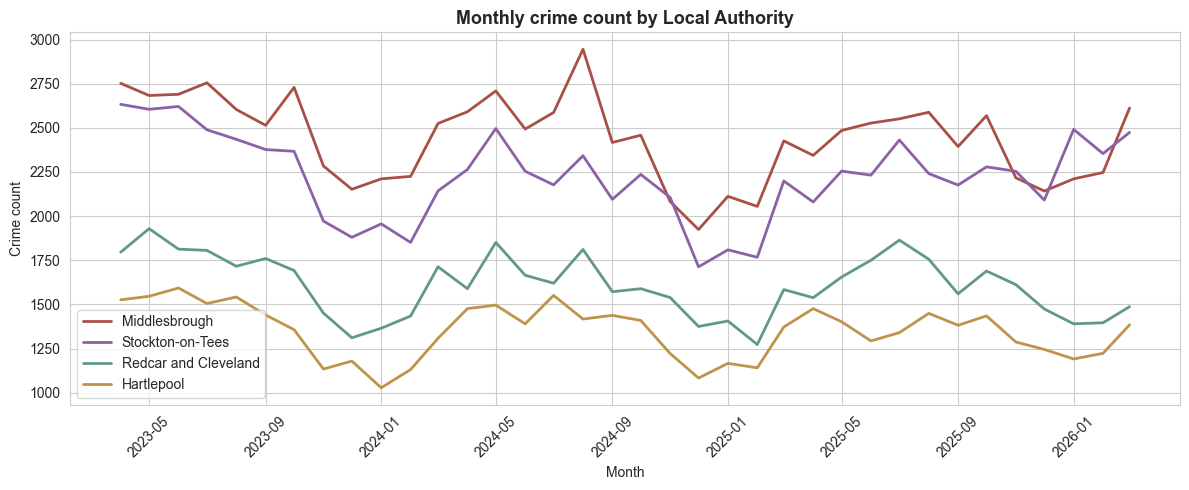

Plot_2_crime_by_la.png is saved in EDA_outputs folder


In [5]:

print("Plot 2:")

la_monthly=crime.groupby(['Month', 'Local_Authority'])['crime_count'].sum().reset_index()
la_monthly['Month_dt']=pd.to_datetime(la_monthly['Month'])



fig, ax=plt.subplots(figsize=(12,5))
colours={'Middlesbrough': "#a85046",
         'Stockton-on-Tees': "#8b61a8",
         'Redcar and Cleveland': "#61978e",
         'Hartlepool': "#c0934b"}

for la in colours:
    subset=la_monthly[la_monthly['Local_Authority']==la]
    ax.plot(subset['Month_dt'], subset['crime_count'], label=la, color=colours[la], linewidth=2)
ax.set_title('Monthly crime count by Local Authority', fontsize=13,fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Crime count')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_2_crime_by_la.png'), dpi=150)
plt.show()
print("Plot_2_crime_by_la.png is saved in EDA_outputs folder")


### Plot 3: Seasonal pattern (average crime by calendar month)

Plot 3:
Plot_3_seasonal_pattern.png saved in EDA_outputs folder


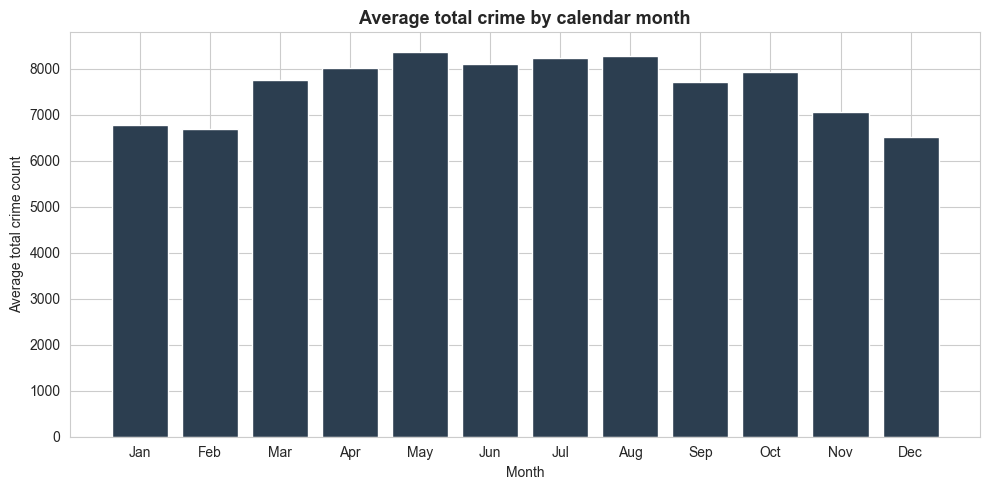

In [6]:

print("Plot 3:")

crime['calendar_month']=pd.to_datetime(crime['Month']).dt.month
seasonal=crime.groupby('calendar_month')['crime_count'].sum().reset_index()

#Average across the number of times each calendar monh appears
month_counts=crime.groupby('calendar_month')['Month'].nunique().reset_index()
month_counts.columns=['calendar_month', 'num_years']
seasonal=seasonal.merge(month_counts)
seasonal['avg_crime']=seasonal['crime_count']/seasonal['num_years']

month_labels= ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun','Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax=plt.subplots(figsize=(10,5))
ax.bar(seasonal['calendar_month'], seasonal['avg_crime'], color='#2c3e50', edgecolor='white' )
ax.set_xticks(range(1,13))
ax.set_xticklabels(month_labels)
ax.set_title('Average total crime by calendar month', fontsize=13,fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Average total crime count')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_3_seasonal_pattern.png'))
print("Plot_3_seasonal_pattern.png saved in EDA_outputs folder")

### Plot 4: Distribution of crime counts across LSOAs

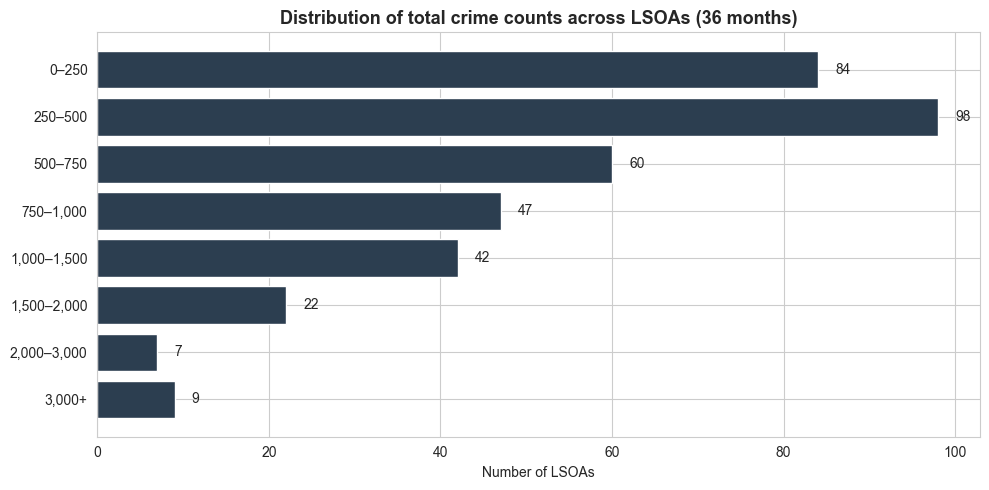

In [7]:
lsoa_totals=crime.groupby('LSOA code')['crime_count'].sum().sort_values(ascending=False)

bins=[0, 250, 500, 750, 1000, 1500, 2000, 3000, lsoa_totals.max()+1]
labels=['0–250', '250–500', '500–750', '750–1,000', '1,000–1,500',
        '1,500–2,000', '2,000–3,000', '3,000+']
groups=pd.cut(lsoa_totals, bins=bins, labels=labels, right=False)
counts=groups.value_counts().reindex(labels)

fig, ax=plt.subplots(figsize=(10, 5))
bars=ax.barh(counts.index, counts.values, color='#2c3e50', edgecolor='white')
ax.set_xlabel('Number of LSOAs')
ax.set_title('Distribution of total crime counts across LSOAs (36 months)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
for bar, v in zip(bars, counts.values):
    ax.text(v + 2, bar.get_y() + bar.get_height()/2, str(v),
            va='center', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_4_LSOA_distribution.png'), dpi=150)
plt.show()

### Plot 5: Top 20 LSOAs by crime volume

Plot 5:


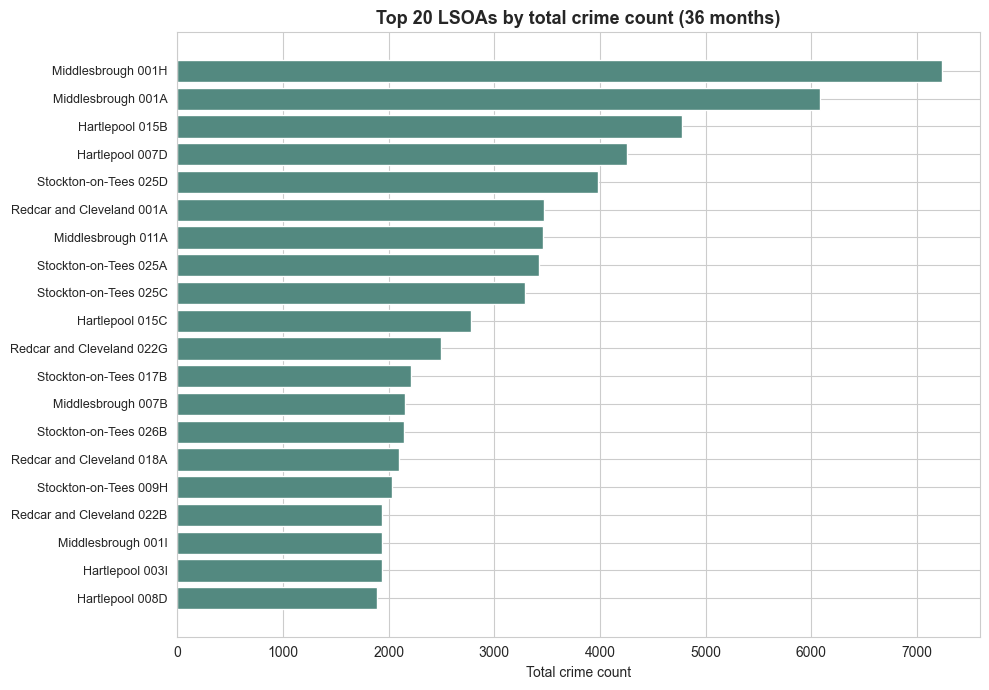

Plot_5_top20_lsoas.png saved in EDA_output folder


In [8]:

print("Plot 5:")

top20=lsoa_totals.head(20)
top20_names=(crime[crime['LSOA code'].isin(top20.index)]
             [['LSOA code', 'LSOA name']].drop_duplicates().set_index('LSOA code'))


fig,ax=plt.subplots(figsize=(10,7))
labels=[top20_names.loc[code, 'LSOA name'] for code in top20.index]
ax.barh(range(len(top20)), top20.values, color="#538980", edgecolor='white')
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(labels,fontsize=9)
ax.invert_yaxis()
ax.set_title('Top 20 LSOAs by total crime count (36 months)', fontsize=13, fontweight='bold')
ax.set_xlabel('Total crime count')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_5_top20_lsoas.png'))
plt.show()
print("Plot_5_top20_lsoas.png saved in EDA_output folder")


### Plot 6: Hotspot turnover analysis

Plot 6:
Plot_6_hotspot_turnover.png saved in EDA_output folder
Hotspot treshold: top 10%=36 LSOAs per month
Mean turnover: 41.6%


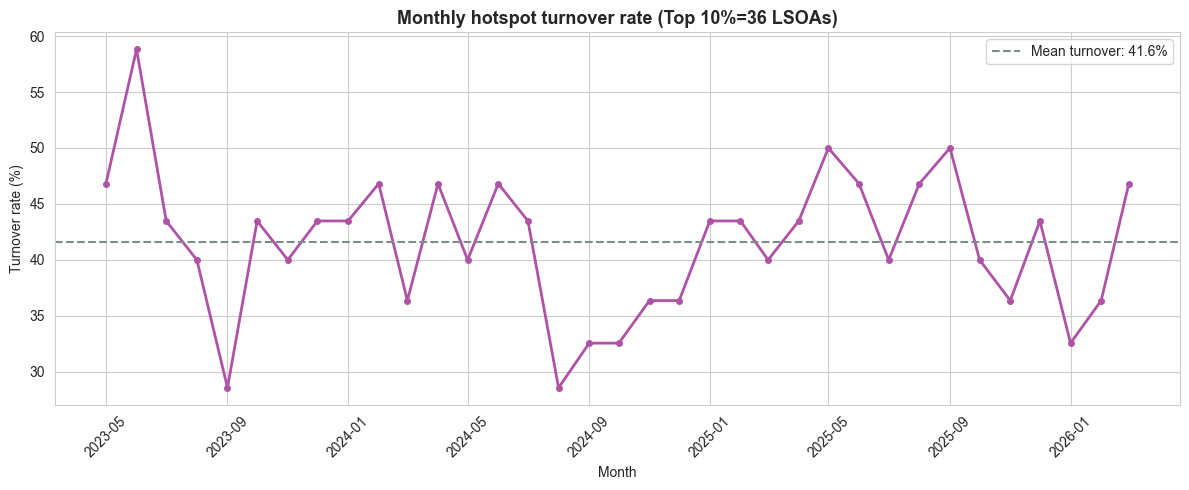

In [9]:

print("Plot 6:")

# Defining hotspots as top 10% of LSOAs by crime count each month
n_lsoas=crime['LSOA code'].nunique()
top_pct=0.10
n_hotspot=max(1,int(n_lsoas*top_pct))

months=sorted(crime['Month'].unique())
hotspot_sets={}

for month in months:
    month_data=crime[crime['Month']==month].sort_values('crime_count',ascending=False)
    hotspot_codes=set(month_data.head(n_hotspot)['LSOA code'].values)
    hotspot_sets[month]=hotspot_codes

#Calculating turnover between consecutive month
turnovers=[]

for i in range(1, len(months)):
    prev=hotspot_sets[months[i-1]]
    curr=hotspot_sets[months[i]]
    #Entered hotspot status
    new_hotspots=curr-prev
    #Left hotspot status
    left_hotspots=prev-curr
    turnover=len(new_hotspots | left_hotspots)/len(prev | curr)*100
    turnovers.append({'month':months[i],
                      'turnover_pct':turnover,
                      'new_hotspots':len(new_hotspots),
                      'left_hotspots':len(left_hotspots),
                      'stable_hotspots':len(prev&curr)})
    
turnover_df=pd.DataFrame(turnovers)
turnover_df['month_dt']=pd.to_datetime(turnover_df['month'])

fig,ax=plt.subplots(figsize=(12,5))
ax.plot(turnover_df['month_dt'], turnover_df['turnover_pct'], color="#ae53a5",
        linewidth=2, marker='o', markersize=4)
ax.axhline(turnover_df['turnover_pct'].mean(), color='#7f8c8c', linestyle='--',
            label=f'Mean turnover: {turnover_df["turnover_pct"].mean():.1f}%')
ax.set_title(f'Monthly hotspot turnover rate (Top {int(top_pct*100)}%={n_hotspot} LSOAs)',
                fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Turnover rate (%)')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_6_hotspot_turnover.png'),dpi=150)
print("Plot_6_hotspot_turnover.png saved in EDA_output folder")

print(f"Hotspot treshold: top {int(top_pct*100)}%={n_hotspot} LSOAs per month")
print(f"Mean turnover: {turnover_df['turnover_pct'].mean():.1f}%")

### Plot 7: Chorpleth map of average monthly crime count

Plot 7:


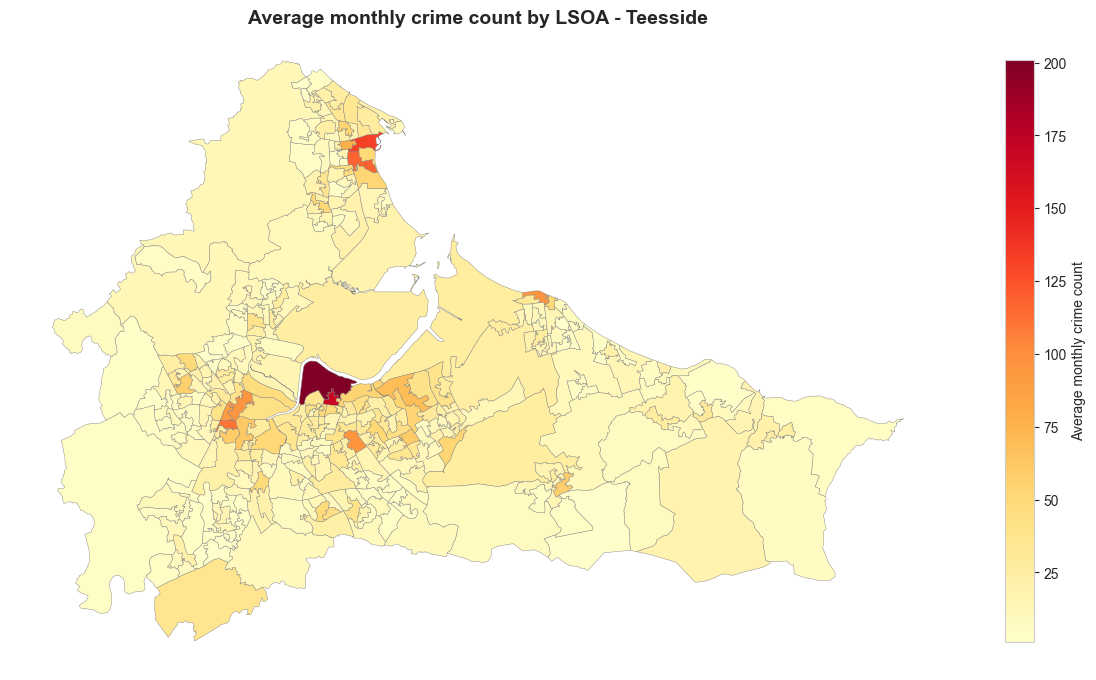

Plot_7_crime_heatmap.png saved in EDA_output folder


In [10]:

print("Plot 7:")

lsoa_avg=crime.groupby('LSOA code')['crime_count'].mean().reset_index()
lsoa_avg.columns=['LSOA21CD', 'avg_crime']

map_data=teesside_gdf.merge(lsoa_avg, on='LSOA21CD', how='left')

fig,ax=plt.subplots(figsize=(12,10))
map_data.plot(column='avg_crime', cmap='YlOrRd', legend=True, ax=ax,
              edgecolors='grey', linewidth=0.3, legend_kwds={'label': 'Average monthly crime count', 'shrink':0.6})

ax.set_title('Average monthly crime count by LSOA - Teesside', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_7_crime_heatmap.png'))
plt.show()
print("Plot_7_crime_heatmap.png saved in EDA_output folder")

### Plot 8: Hotspot stability map

Plot 8:


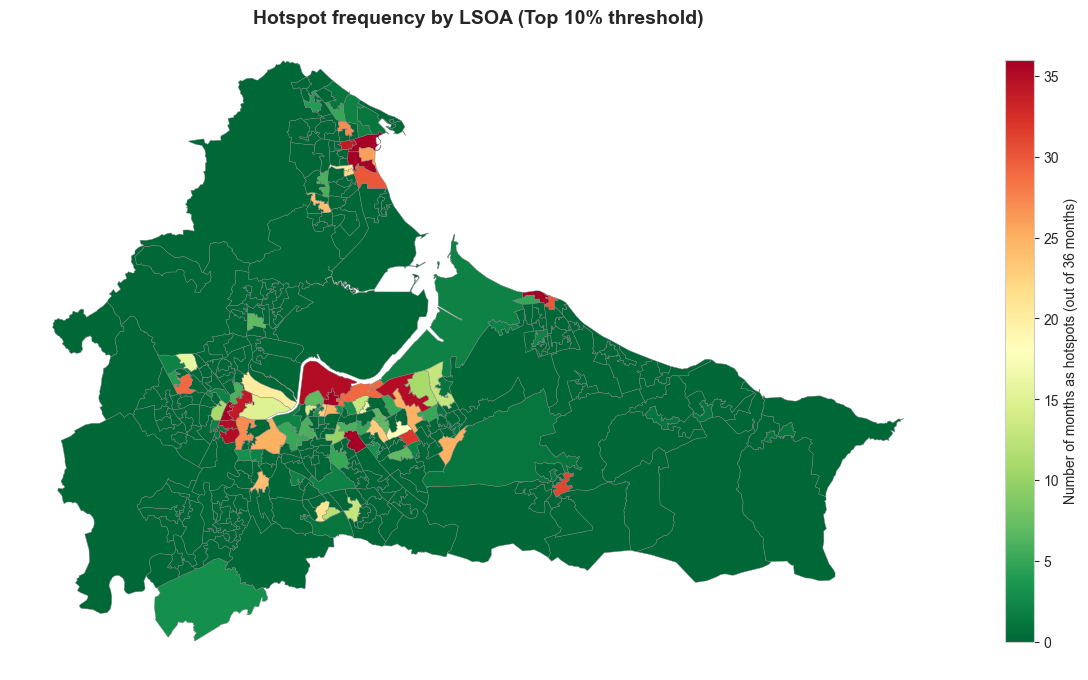

Plot_8_hotspot_stability.png saved in EDA_output folder


In [11]:

print("Plot 8:")

#Counting how many months each LSOA was a hotspot
hotspot_freq={}
for code in crime['LSOA code'].unique():
    count=sum(1 for month in months if code in hotspot_sets[month])
    hotspot_freq[code]=count

freq_df=pd.DataFrame(list(hotspot_freq.items()), columns=['LSOA21CD', 'months_as_hotspot'])
map_data2=teesside_gdf.merge(freq_df, on='LSOA21CD', how='left')

fig,ax=plt.subplots(figsize=(12,10))
map_data2.plot(column='months_as_hotspot', cmap='RdYlGn_r', legend=True, ax=ax, edgecolor='grey',
               linewidth=0.3, legend_kwds={'label': 'Number of months as hotspots (out of 36 months)', 'shrink':0.6})
ax.set_title(f'Hotspot frequency by LSOA (Top {int(top_pct*100)}% threshold)', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_8_hotspot_stability.png'))
plt.show()
print("Plot_8_hotspot_stability.png saved in EDA_output folder" )




